# EmbeddingGemma 2 - Introdução e aplicações

**Fontes:** [guia do Google](https://developers.googleblog.com/en/embeddinggemma-2-the-developer-guide/) · [model card](https://huggingface.co/google/embeddinggemma-2) · [Sentence Transformers](https://www.sbert.net/)

## 1. Preparar o ambiente

Usaremos `sentence-transformers` 6.1.0 ou superior. Execute a instalação uma vez e, se necessário, reinicie o kernel.

In [1]:
!pip install -qU sentence-transformers transformers

## 2. Carregar apenas texto e código

Desativar visão e áudio reduz a configuração de 740M para **270M parâmetros**. O modelo usa `float32` por padrão; isso é adequado para a maioria das CPUs. Em GPUs com suporte, `bfloat16` pode reduzir memória. Evite `float16` com este modelo.

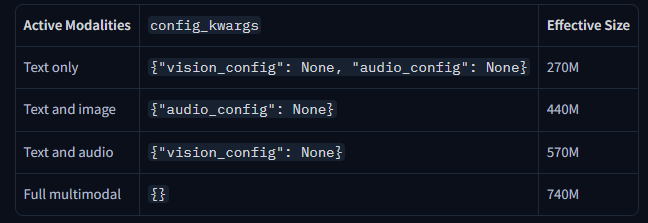

In [2]:
from sentence_transformers import SentenceTransformer
import numpy as np
import torch

dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32

MODEL_ID = "google/embeddinggemma-2"

model = SentenceTransformer(
    MODEL_ID,
    config_kwargs={"vision_config": None,
                   "audio_config": None,
                   "torch_dtype": dtype},
)
print("Modelo carregado:", MODEL_ID)

modules.json:   0%|          | 0.00/413 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/1.56k [00:00<?, ?B/s]

README.md:   0%|          | 0.00/21.7k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/747 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.46k [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 32.2MB            

tokenizer.json: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/90.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/97.0 [00:00<?, ?B/s]

Modelo carregado: google/embeddinggemma-2


## 3. O primeiro embedding

Um texto vira um vetor com **768 números**. `normalize_embeddings=True` deixa o vetor com norma 1, facilitando a comparação por similaridade de cosseno.

In [3]:
texto = "Como faço para redefinir minha senha?"
embedding = model.encode(texto, normalize_embeddings=True)

print("Formato:", embedding.shape)
print("Primeiros valores:", embedding[:5])

Formato: (768,)
Primeiros valores: [-0.00160217 -0.00012064  0.04150391 -0.02233887  0.0267334 ]


## 4. Similaridade: comparar significados

Em uma tarefa simétrica, todas as frases usam o mesmo prompt: `SentenceSimilarity`. Quanto maior o score de cosseno, maior a proximidade segundo o modelo.

In [8]:
frases = [
    "Esqueci minha senha e preciso criar outra.",
    "Como recuperar o acesso à minha conta?",
    "Qual é a previsão do tempo para amanhã?",
]
vetores = model.encode(
    frases,
    prompt_name="SentenceSimilarity",
    normalize_embeddings=True,
)
similaridades = model.similarity(vetores, vetores)

for i, frase in enumerate(frases):
    print(f"\n{frase}")
    for j, outra in enumerate(frases):
        print(f"  {similaridades[i, j].item():.3f} | {outra}")


Esqueci minha senha e preciso criar outra.
  1.000 | Esqueci minha senha e preciso criar outra.
  0.855 | Como recuperar o acesso à minha conta?
  0.717 | Qual é a previsão do tempo para amanhã?

Como recuperar o acesso à minha conta?
  0.855 | Esqueci minha senha e preciso criar outra.
  1.000 | Como recuperar o acesso à minha conta?
  0.746 | Qual é a previsão do tempo para amanhã?

Qual é a previsão do tempo para amanhã?
  0.717 | Esqueci minha senha e preciso criar outra.
  0.746 | Como recuperar o acesso à minha conta?
  1.000 | Qual é a previsão do tempo para amanhã?


## 5. Mini busca semântica

Na busca, consulta e documentos têm papéis diferentes. Por isso usamos `SearchQuery` e `Document`.


**Ponto importante**: O EmbeddingGemma 2 é treinado com prefixos curtos de instruções de tarefas adicionados às entradas de texto. Usar o prefixo correto melhora a qualidade; omiti-lo ainda funciona, mas reduz a precisão.

Documentos com um título real devem ser formatados como `title: {title} | text: {content}`.

Use title: `none` quando nenhum título estiver disponível.

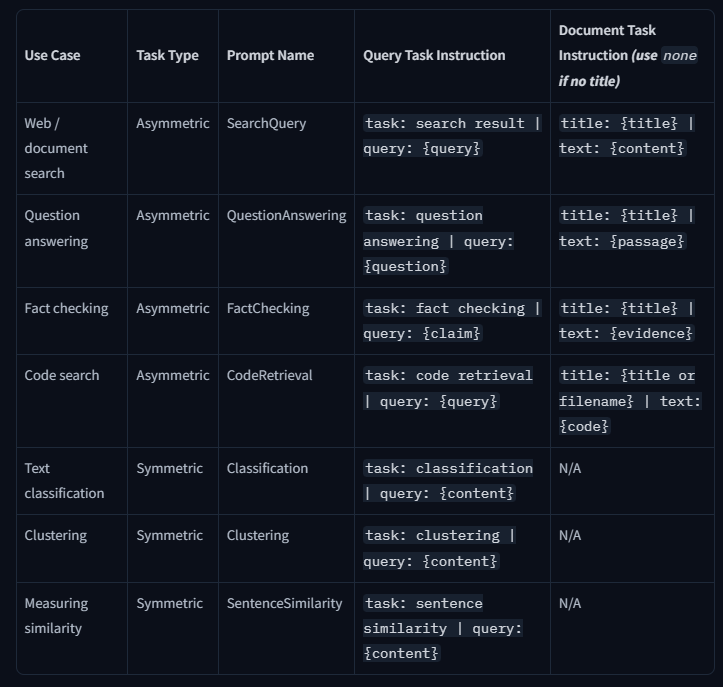

In [10]:
documentos = [
    "Para redefinir a senha, abra Configurações, selecione Segurança e siga as instruções.",
    "O prazo para devolução de compras é de sete dias após o recebimento.",
    "O boleto vence cinco dias úteis após a emissão.",
    "Se a conta estiver bloqueada, confirme seu e-mail e solicite um link de recuperação.",
    "O frete é calculado pelo CEP e pelo peso do pacote.",
]
docs_emb = model.encode(
    documentos,
    prompt_name="Document",
    normalize_embeddings=True,
)

def buscar(pergunta, k=5):
    query_emb = model.encode(
        pergunta,
        prompt_name="SearchQuery",
        normalize_embeddings=True,
    )
    scores = model.similarity(query_emb, docs_emb)[0]
    indices = scores.argsort(descending=True)[:k].tolist()
    return [(documentos[i], scores[i].item()) for i in indices]

for texto, score in buscar("Não consigo entrar na minha conta"):
    print(f"{score:.3f} | {texto}")

0.776 | Se a conta estiver bloqueada, confirme seu e-mail e solicite um link de recuperação.
0.750 | Para redefinir a senha, abra Configurações, selecione Segurança e siga as instruções.
0.623 | O prazo para devolução de compras é de sete dias após o recebimento.
0.595 | O frete é calculado pelo CEP e pelo peso do pacote.
0.593 | O boleto vence cinco dias úteis após a emissão.


## 6. Classificação sem treinar um classificador

Podemos comparar cada mensagem com descrições de categorias. Como todas as entradas participam da mesma tarefa, usamos `Classification` nos dois lados. Isto é um experimento de **zero-shot classification**, não um modelo treinado no seu domínio.

In [11]:
categorias = [
    "Dúvidas sobre pagamento, cobrança ou boleto",
    "Problemas de acesso, login ou senha",
    "Entrega, frete ou rastreamento de pedido",
]
mensagens = [
    "Meu boleto ainda não chegou",
    "Não recebi o código para entrar",
    "Onde está meu pacote?",
]
cat_emb = model.encode(categorias, prompt_name="Classification", normalize_embeddings=True)
msg_emb = model.encode(mensagens, prompt_name="Classification", normalize_embeddings=True)
scores = model.similarity(msg_emb, cat_emb)

for i, mensagem in enumerate(mensagens):
    indice = scores[i].argmax().item()
    print(f"{mensagem} -> {categorias[indice]} ({scores[i, indice].item():.3f})")

Meu boleto ainda não chegou -> Dúvidas sobre pagamento, cobrança ou boleto (0.753)
Não recebi o código para entrar -> Problemas de acesso, login ou senha (0.852)
Onde está meu pacote? -> Entrega, frete ou rastreamento de pedido (0.788)


## 7. Matryoshka: comparar 768, 256 e 128 dimensões

Vetores menores ocupam menos espaço e podem acelerar a busca. Ao truncar, **renormalize** e use a mesma dimensão para consulta e documentos. Compare também o ranking, não apenas o tamanho.

In [12]:
consulta = "Como recuperar minha conta?"
for dim in [768, 256, 128]:
    q = model.encode(consulta, prompt_name="SearchQuery",
                     truncate_dim=dim, normalize_embeddings=True)
    d = model.encode(documentos, prompt_name="Document",
                     truncate_dim=dim, normalize_embeddings=True)
    scores = model.similarity(q, d)[0]
    melhor = scores.argmax().item()
    print(f"\n{dim}d | {d.nbytes / 1024:.1f} KiB no mini índice")
    print(f"Top-1 ({scores[melhor].item():.3f}): {documentos[melhor]}")


768d | 15.0 KiB no mini índice
Top-1 (0.835): Se a conta estiver bloqueada, confirme seu e-mail e solicite um link de recuperação.

256d | 5.0 KiB no mini índice
Top-1 (0.847): Se a conta estiver bloqueada, confirme seu e-mail e solicite um link de recuperação.

128d | 2.5 KiB no mini índice
Top-1 (0.891): Se a conta estiver bloqueada, confirme seu e-mail e solicite um link de recuperação.


## 8. Busca em código por linguagem natural

`CodeRetrieval` orienta a consulta para recuperação de código. No documento, incluímos um nome de arquivo no formato recomendado pelo model card.

In [19]:
# Uma pequena base: (arquivo, código)
codigos = [
    ("frete.py", "def calcular_frete(peso, cep):\n    return 10 + peso * 2"),
    ("auth.py", "def validar_token(token):\n    return token is not None and len(token) > 20"),
    ("texto.py", "def normalizar_texto(texto):\n    return texto.strip().lower()"),
]
entradas = [f"title: {arquivo} | text: {codigo}" for arquivo, codigo in codigos]
code_emb = model.encode(entradas, normalize_embeddings=True)
query = model.encode("verificar se um token é válido",
                     prompt_name="CodeRetrieval", normalize_embeddings=True)
scores = model.similarity(query, code_emb)[0]

for i in scores.argsort(descending=True).tolist():
    print(f"{scores[i].item():.3f} | {codigos[i][0]}")

0.800 | auth.py
0.638 | frete.py
0.627 | texto.py


## 9. Opcional: buscar imagens com texto

Este exemplo precisa de arquivos próprios (`praia.jpg`, `montanha.jpg`, `cachorro.jpg`) e dos recursos de imagem. Se necessário, instale `sentence-transformers[image]`. A configuração de visão desativa apenas o áudio e carrega **440M parâmetros**.

In [24]:
from sentence_transformers import SentenceTransformer
import numpy as np
import torch

dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float32

MODEL_ID = "google/embeddinggemma-2"

model = SentenceTransformer(
    MODEL_ID,
    config_kwargs={ "audio_config": None,
                   "torch_dtype": dtype},
)
print("Modelo carregado:", MODEL_ID)

Loading weights:   0%|          | 0/624 [00:00<?, ?it/s]

Modelo carregado: google/embeddinggemma-2


In [31]:
imagens = ["praia.jpg", "montanha.jpg", "pug.jpg"]
docs = [
    {"image": caminho}
    for caminho in imagens
]
docs

[{'image': 'praia.jpg'}, {'image': 'montanha.jpg'}, {'image': 'pug.jpg'}]

In [30]:
image_emb = model.encode(docs, normalize_embeddings=True)
query = model.encode("um cachorro fofinho",
                            prompt_name="SearchQuery", normalize_embeddings=True)
scores = model.similarity(
    query,
    image_emb,
)[0]
for i in scores.argsort(descending=True).tolist():
    print(f"{scores[i].item():.3f} | {imagens[i]}")

0.670 | pug.jpg
0.579 | praia.jpg
0.579 | montanha.jpg


O modelo compara a descrição textual com a representação visual que aprendeu a produzir (cross-modal retrieval).

**Exemplos de aplicações:**

- Encontrar fotos de produtos a partir de uma descrição

- Pesquisar imagens em um acervo sem depender de etiquetas manuais

- Localizar diagramas relevantes em documentação técnica

- Encontrar imagens que correspondam a uma descrição de uma cena

Uma única entrada pode combinar texto com imagens, vídeo e áudio, usando um único contexto compartilhado de 8.192 tokens.

A posição de cada item de mídia dentro da sequência é marcada no texto usando marcadores de posição do vocabulário do modelo:

- <|image|> marca a posição da entrada de imagem

- <|video|> marca a posição da entrada de vídeo

- <|audio|> marca a posição da entrada de áudio


Por exemplo, uma lista de produtos indexada para pesquisa pode ser codificada como:

In [ ]:
emb_interleaved = model.encode([{
    "text": """Waterproof running shoes.
            <|image|> Featuring a breathable mesh upper.
            <|image|> Grip test on wet rock:
            <|video|>""",
    "image": ["shoe.jpg", "mesh.jpg"],
    "video": "demo.mp4",
}])